In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, cohen_kappa_score,
    matthews_corrcoef, confusion_matrix, roc_curve, precision_recall_curve
)

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'

In [2]:
data_path = "womens_clothing_classification_dataset.csv"
if not os.path.exists(data_path):
    data_path = os.path.join("30-10-2026", "Task 3", "womens_clothing_classification_dataset.csv")

df = pd.read_csv(data_path)
df['Full_Review_Text'] = df['Full_Review_Text'].fillna('')

sample_df = df[['Full_Review_Text', 'Recommended IND']].sample(n=6000, random_state=42).reset_index(drop=True)

train_texts, test_texts, train_labels, test_labels = train_test_split(
    sample_df['Full_Review_Text'].tolist(),
    sample_df['Recommended IND'].tolist(),
    test_size=0.20,
    random_state=42,
    stratify=sample_df['Recommended IND']
)
print(f"Constructed Train Set: {len(train_texts)} reviews | Test Set: {len(test_texts)} reviews")

Constructed Train Set: 4800 reviews | Test Set: 1200 reviews


In [3]:
history_csv = "transformer_training_history.csv"
if not os.path.exists(history_csv):
    history_csv = os.path.join("30-10-2026", "Task 3", "transformer_training_history.csv")

df_history = pd.read_csv(history_csv)
display(df_history)

,Epoch,Train_Loss,Val_Loss,Val_Accuracy,Val_Macro_F1
0,1,0.4198,0.3722,0.8392,0.6110
1,2,0.3338,0.3418,0.8550,0.7431
2,3,0.2727,0.3212,0.8717,0.7842
3,4,0.2265,0.3257,0.8717,0.7850
4,5,0.1790,0.3209,0.8833,0.7925


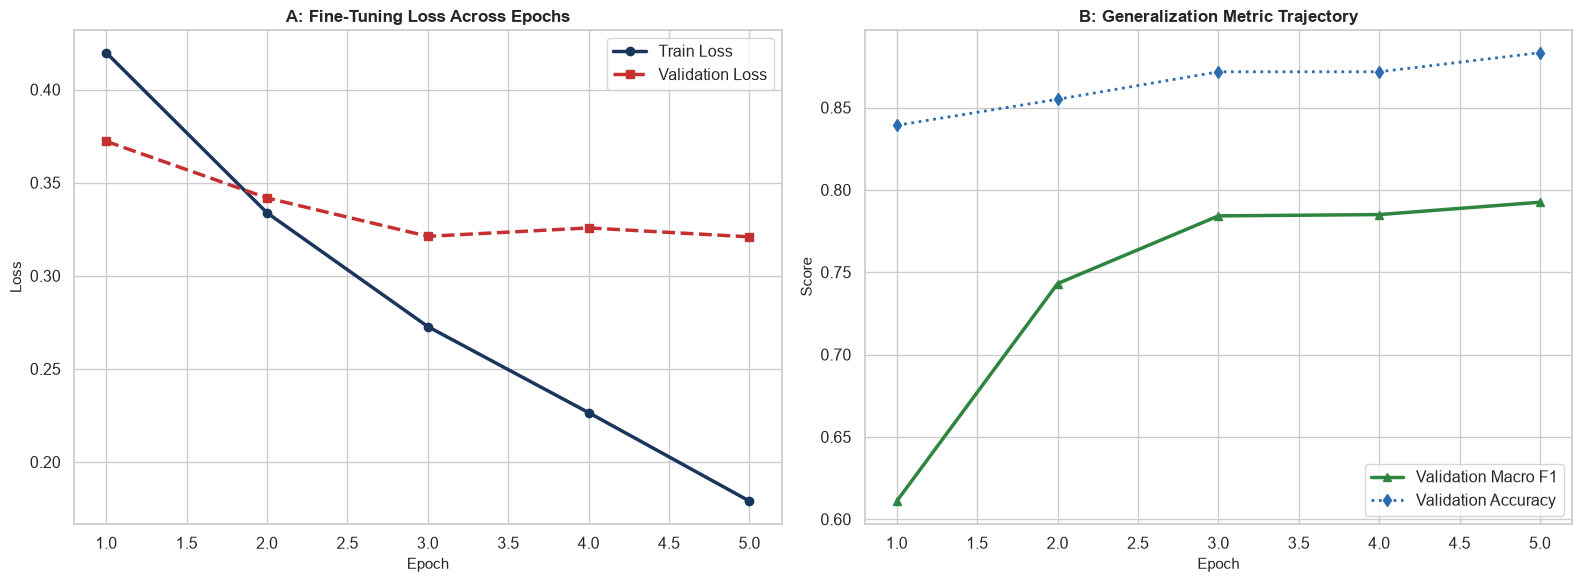

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(df_history['Epoch'], df_history['Train_Loss'], marker='o', color='#1A365D', linewidth=2.5, label='Train Loss')
axes[0].plot(df_history['Epoch'], df_history['Val_Loss'], marker='s', color='#C53030', linewidth=2.5, linestyle='--', label='Validation Loss')
axes[0].set_title("A: Fine-Tuning Loss Across Epochs", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Epoch", fontsize=11)
axes[0].set_ylabel("Loss", fontsize=11)
axes[0].legend(loc='upper right', frameon=True)

axes[1].plot(df_history['Epoch'], df_history['Val_Macro_F1'], marker='^', color='#2E8540', linewidth=2.5, label='Validation Macro F1')
axes[1].plot(df_history['Epoch'], df_history['Val_Accuracy'], marker='d', color='#2B6CB0', linewidth=2.0, linestyle=':', label='Validation Accuracy')
axes[1].set_title("B: Generalization Metric Trajectory", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Epoch", fontsize=11)
axes[1].set_ylabel("Score", fontsize=11)
axes[1].legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.show()

In [5]:
eval_csv = "transformer_evaluation_metrics_benchmark.csv"
if not os.path.exists(eval_csv):
    eval_csv = os.path.join("30-10-2026", "Task 3", "transformer_evaluation_metrics_benchmark.csv")

df_eval = pd.read_csv(eval_csv)
display(df_eval)

,Model_Architecture,Accuracy,Precision,Recall,F1_Score,Macro_F1,ROC_AUC,PR_AUC,Cohen_Kappa,MCC,Single_Sample_Latency_us,Model_Size_MB
0,Pre-trained Transformer (FP32),0.8833,0.9187,0.9411,0.9298,0.7925,0.8952,0.9727,0.5853,0.5867,1314.2,1.52
1,Quantized Transformer (INT8 PTQ),0.8833,0.9187,0.9411,0.9298,0.7925,0.8953,0.9728,0.5853,0.5867,1785.2,1.51


In [6]:
lat_csv = "transformer_inference_latency_profiles.csv"
if not os.path.exists(lat_csv):
    lat_csv = os.path.join("30-10-2026", "Task 3", "transformer_inference_latency_profiles.csv")

df_lat = pd.read_csv(lat_csv)
display(df_lat)

,Batch_Size,FP32_Batch_Latency_ms,FP32_Per_Sample_Latency_us,INT8_Batch_Latency_ms,INT8_Per_Sample_Latency_us,Latency_Speedup
0,1,1.31,1314.2,1.79,1785.2,0.74
1,4,2.79,697.8,3.26,814.0,0.86
2,16,9.93,620.6,9.26,578.7,1.07
3,64,36.81,575.1,36.89,576.3,1.00


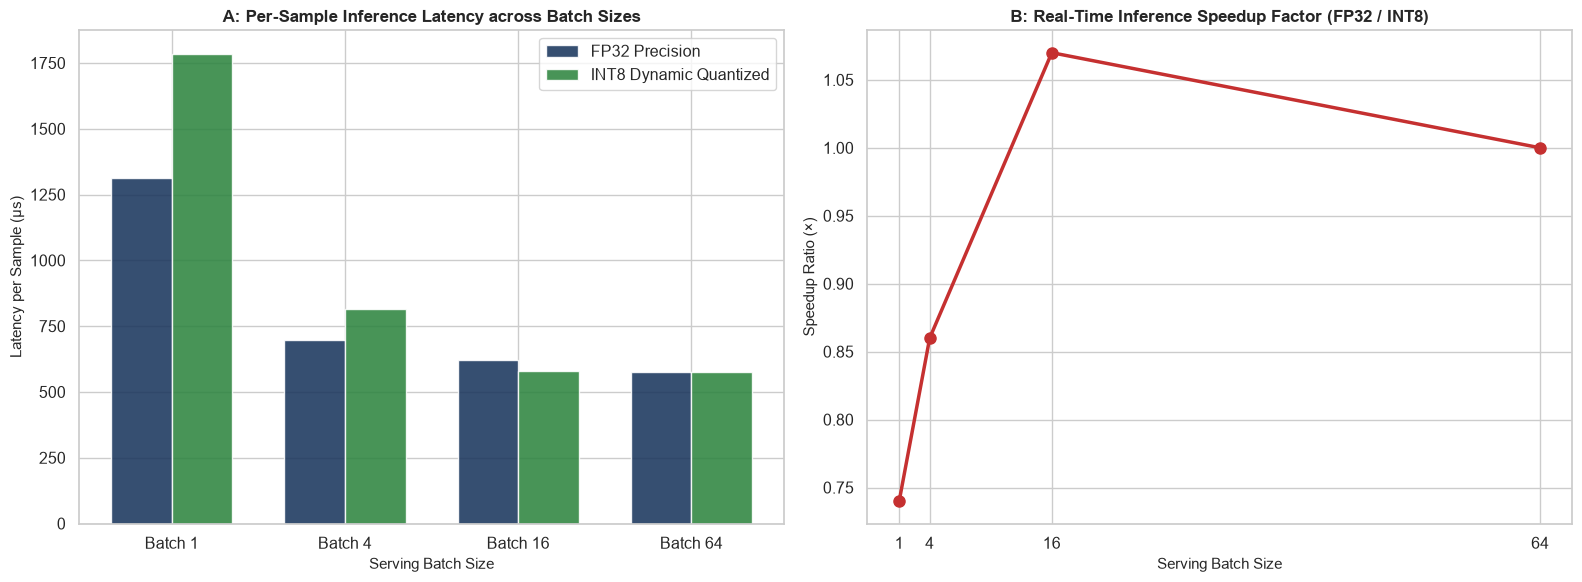

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

x_pos = np.arange(len(df_lat))
width = 0.35

axes[0].bar(x_pos - width/2, df_lat['FP32_Per_Sample_Latency_us'], width, label='FP32 Precision', color='#1A365D', alpha=0.88)
axes[0].bar(x_pos + width/2, df_lat['INT8_Per_Sample_Latency_us'], width, label='INT8 Dynamic Quantized', color='#2E8540', alpha=0.88)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels([f"Batch {b}" for b in df_lat['Batch_Size']])
axes[0].set_title("A: Per-Sample Inference Latency across Batch Sizes", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Serving Batch Size", fontsize=11)
axes[0].set_ylabel("Latency per Sample (\u03bcs)", fontsize=11)
axes[0].legend(loc='upper right', frameon=True)

axes[1].plot(df_lat['Batch_Size'], df_lat['Latency_Speedup'], marker='o', color='#C53030', linewidth=2.5, markersize=8)
axes[1].set_title("B: Real-Time Inference Speedup Factor (FP32 / INT8)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Serving Batch Size", fontsize=11)
axes[1].set_ylabel("Speedup Ratio (\u00d7)", fontsize=11)
axes[1].set_xticks(df_lat['Batch_Size'])

plt.tight_layout()
plt.show()